*openmobisim tutorials* · [00 · overview](00_getting_started.ipynb) · ← [06 · Parameters and experiments](06_parameters_and_experiments.ipynb) · [08 · Performance](08_performance.ipynb) → · [documentation](https://openmobisim.github.io)

# 07 · Validation

Does the simulator compute what it says it computes? This notebook checks it three ways, each small enough to follow:

1. **By hand**, on the toy network: a free-flow trip, a queue at a signal, a saturated merge, each against the value
   worked out on paper from the network's own parameters.
2. **Against queueing theory**: a bottleneck loaded above its capacity, against the closed-form delay of a
   deterministic queue.
3. **Against a published benchmark**: Sioux Falls, against its static user equilibrium (the TNTP reference), with
   what a dynamic model should and should not share with it.

The simulator's own test suite holds many more cases (every rule of the loading, the link transmission model's
textbook cases against a macroscopic reference, transit, parking, choice); these are the ones worth seeing.

**Download** {download}`this notebook <../_static/notebooks/07_validation.ipynb>` or {download}`all ten <../_static/notebooks/openmobisim_notebooks.zip>` (a zip), without their outputs. The Installation section below installs openmobisim; its last command, `openmobisim notebooks`, copies the same ten into a folder and opens the first in JupyterLab.

---

## Installation

> Skip this if `import openmobisim` already works in this notebook. **One install is all there is:**
> `pip install "openmobisim[all]"` brings the simulator and everything the ten tutorials use (JupyterLab,
> matplotlib for the figures, pandas, polars and pyarrow for the tables); nothing is installed later. Find the case
> that matches yours and copy its commands, in order. Each needs Python 3.11 or newer.
>
> **A new conda environment** (any system; openmobisim is on PyPI, so pip installs it into the environment):
>
> ```bash
> conda create -y -n openmobisim python=3.12
> conda activate openmobisim
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on macOS or Linux** (in a terminal):
>
> ```bash
> python3 -m venv openmobisim
> source openmobisim/bin/activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> **A new venv on Windows** (in the Command Prompt):
>
> ```bat
> py -m venv openmobisim
> openmobisim\Scripts\activate
> pip install "openmobisim[all]"
> openmobisim notebooks
> ```
>
> The last line copies these ten notebooks into `./openmobisim-notebooks` and opens them in JupyterLab. In VS Code or
> PyCharm, open a notebook and choose the `openmobisim` environment's Python as its kernel instead.
>
> **Into the environment this notebook already runs in**: paste this into a new code cell, run it, then restart the
> kernel.
>
> ```python
> %pip install "openmobisim[all]"
> ```

---

In [1]:
import heapq
from collections import defaultdict

import numpy as np
import openmobisim as ms
import pandas as pd
from openmobisim import viz

net = ms.examples.toy_network()
ids = net.link_ids()
link = {name: ids.index(name) for name in ("a1", "a2", "a3", "a4", "m1", "c1")}
length, ff, cap = net.link_length_m(), net.link_free_flow_s(), net.link_capacity_pcu_h()


def trip(who, origin, destination, depart_s):
    o, d = net.node_lonlat(origin), net.node_lonlat(destination)
    return (who, 0, o[0], o[1], d[0], d[1], depart_s, "commuter", None, None)


def single(trips, flow_level=2, **kwargs):
    """One loading, everyone on their (only) route: no iterations to blur a hand value."""
    return ms.Scenario.from_parts(net, trips, flow_level=flow_level, equilibration="free_flow", **kwargs).run(
        "validation", quiet=True, overwrite=True  # one folder, rewritten by each case
    )

## 1 · By hand

**Free flow.** One car from `W` to `D1` crosses `a1` (300 m, ending at the signal `S`), `a2`, `a3`, the three 4-m
pieces `c1`–`c3` and `a4`. Its time is the sum of the links' free-flow times: length over speed, plus the signal's
**control delay** on `a1` (Webster's uniform delay at the assumed cycle, green share and degree of saturation).
Times are recorded in whole seconds, rounded down.

In [2]:
route = ["a1", "a2", "a3", "c1", "c2", "c3", "a4"]
by_hand = sum(ff[ids.index(n)] for n in route)
rows = {}
for level, what in ((0, "free flow"), (2, "point queue"), (4, "full model")):
    rows[what] = single([trip("solo", "W", "D1", 0)], flow_level=level).mean_travel_time_s
pd.DataFrame({"simulated (s)": rows, "by hand (s)": np.floor(by_hand)})

,simulated (s),by hand (s)
free flow,165.0,165.0
point queue,165.0,165.0
full model,165.0,165.0


**A queue at a signal.** Twenty cars leave `W` three seconds apart for `M`. They reach the stop line faster than the
signal lets them through — one every `h_s = 3600 / (capacity × green share)` seconds — so a queue forms: car `k`
passes the stop line at `36 + h_s·k`, waits the control delay, and reaches `M` 24 s later (`a2`). Its trip takes
`⌊80.554 + h_s·k⌋ − 3k` seconds.

In [3]:
green = ms.network_options()["signal_green_fraction"]
h_s = 3600 / (cap[link["a1"]] * green)
k = np.arange(20)
hand = np.floor(ff[link["a1"]] + ff[link["a2"]] + h_s * k) - 3 * k
queue = single([trip(f"q{i}", "W", "M", 3 * i) for i in range(20)])
pd.DataFrame({"simulated": [queue.mean_travel_time_s], "by hand": [hand.mean()]}, index=["mean trip (s)"]).round(2)

,simulated,by hand
mean trip (s),102.4,102.4


**A saturated merge.** At `M`, a one-lane road (`a2`, from `S`) and a two-lane road (`m1`, from `N2`) merge into one
lane (`a3`). When both are full, the loading shares the road ahead in proportion to the approaches' capacities
(Daganzo's merge rule): one third from `a2`, two thirds from `m1`, together `a3`'s capacity.

In [4]:
streams = [trip(f"s{i}", "S", "D1", 2 * i) for i in range(900)] + [trip(f"n{i}", "N2", "D1", i) for i in range(1800)]
merge = single(streams, link_bin_s=60)
bins = merge.link_bins("road")
frame = pd.DataFrame({"bin": bins.bins(), "link": bins.links(), "pcu": bins.pcu()})
steady = frame[(frame["bin"] >= 5) & (frame["bin"] < 25)]  # minutes 5-25: both queues standing
per_h = steady.groupby("link")["pcu"].sum() / (20 / 60)
share = per_h[link["a2"]] / (per_h[link["a2"]] + per_h[link["m1"]])
pd.DataFrame(
    {"simulated": [per_h[link["a2"]], per_h[link["m1"]], share],
     "by hand": [cap[link["a3"]] / 3, 2 * cap[link["a3"]] / 3, 1 / 3]},
    index=["a2 discharge (PCU/h)", "m1 discharge (PCU/h)", "a2's share"],
).round(3)  # fmt: skip

,simulated,by hand
a2 discharge (PCU/h),465.000,466.667
m1 discharge (PCU/h),933.000,933.333
a2's share,0.333,0.333


The same merge on the map, minutes 5–25: both approaches red with their queues, `a3` carrying its capacity.

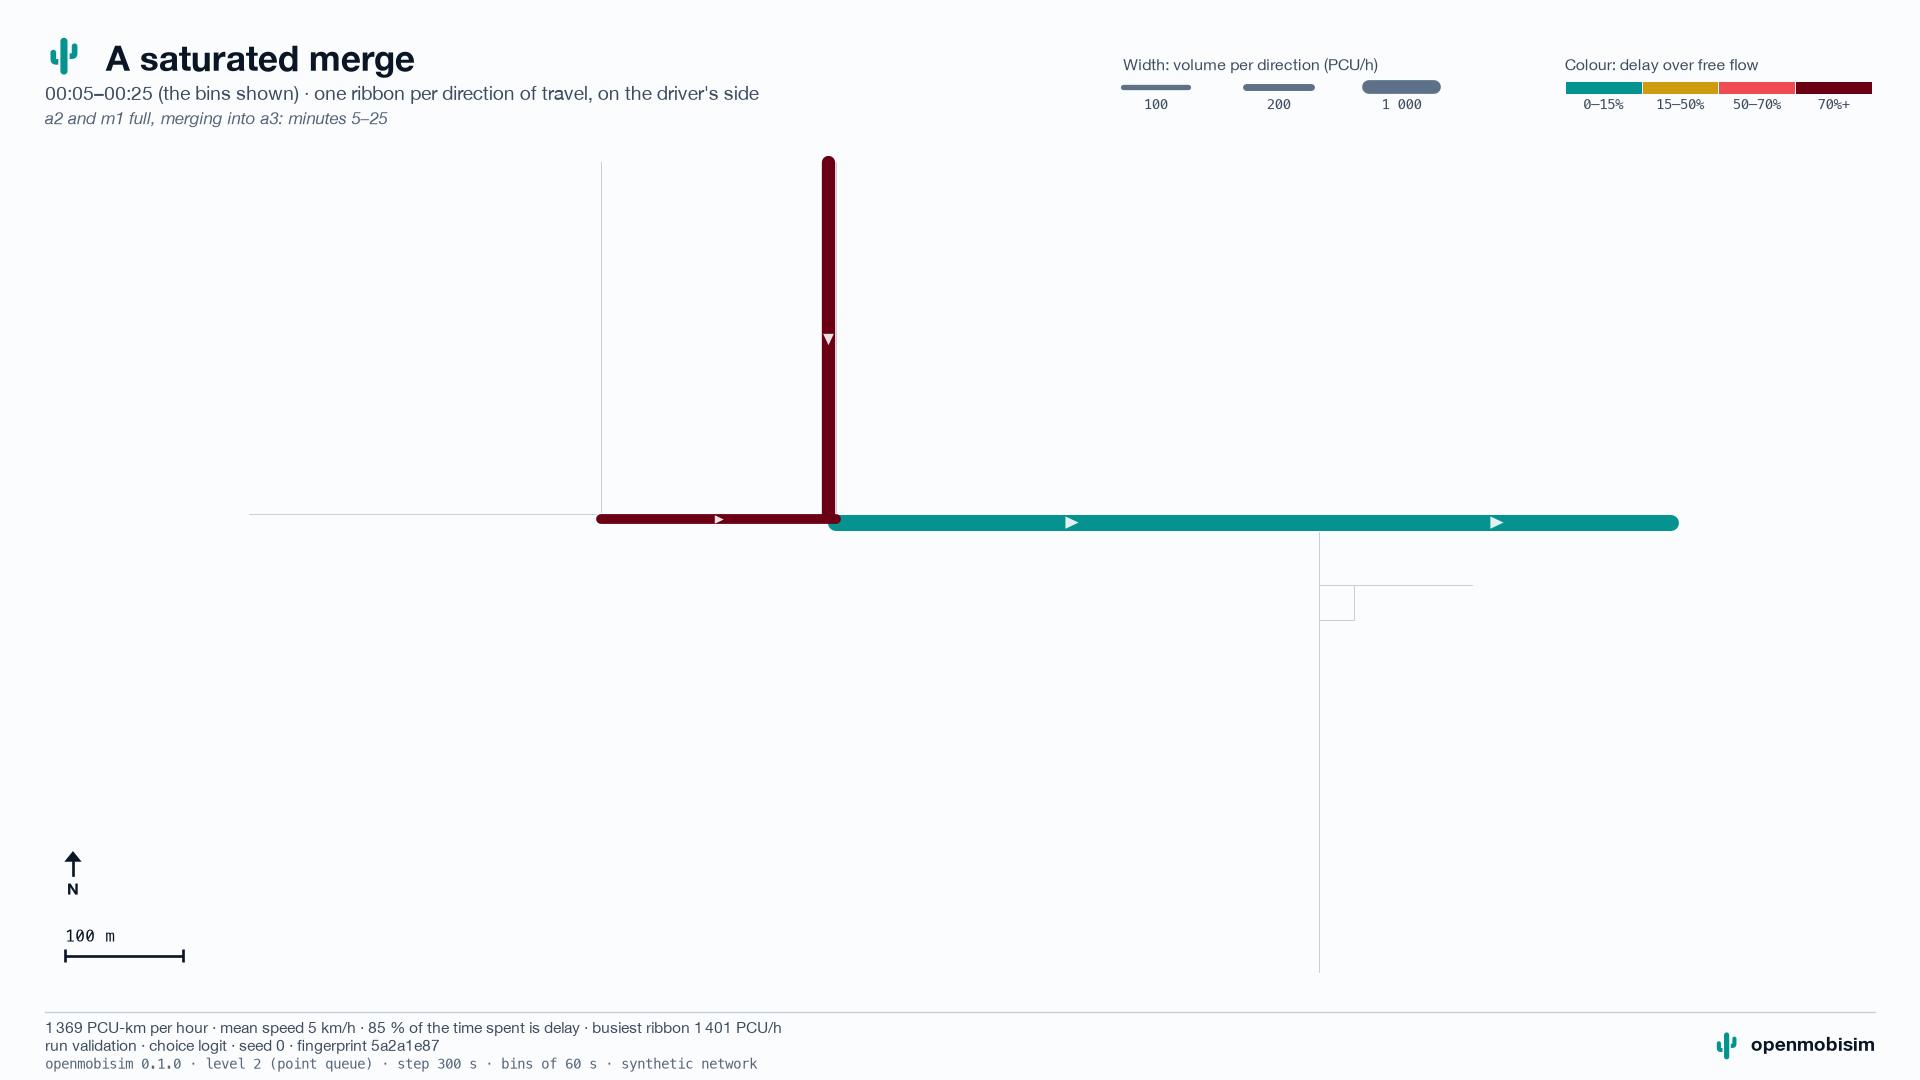

In [5]:
viz.map_link(merge, bins=(5, 25), title="A saturated merge", note="a2 and m1 full, merging into a3: minutes 5–25")

## 2 · A bottleneck against queueing theory

A **deterministic queue**: vehicles arrive at rate λ for a time T at a bottleneck that serves μ < λ. The queue grows
at λ − μ until T and then empties at μ, by `T' = λT/μ`; the total delay is the area between the arrival and departure
curves, **½ · (λ − μ) · T · T'**. Here 2 000 cars an hour for 30 minutes come down `m1` (two lanes) into `a3` (one
lane, 1 400 PCU/h). The point queue (the default loading) is this model at every bottleneck; the full model adds the
queue's length, which can then reach back to the links upstream.

In [6]:
lam, T = 2000.0, 0.5
mu = cap[link["a3"]]
n = int(lam * T)
cars = [trip(f"b{i}", "N2", "D1", round(i * 3600 / lam)) for i in range(n)]
free_s = sum(ff[ids.index(x)] for x in ["m1", "a3", "c1", "c2", "c3", "a4"])
theory_h = 0.5 * (lam - mu) * T * (lam * T / mu)
rows = {}
for level, what in ((2, "point queue"), (4, "full model")):
    run = single(cars, flow_level=level)
    rows[what] = (run.total_travel_time_s - n * np.floor(free_s)) / 3600
pd.DataFrame({"total delay (vehicle-hours)": {**rows, "theory": theory_h}}).round(2)

,total delay (vehicle-hours)
point queue,107.04
full model,107.04
theory,107.14


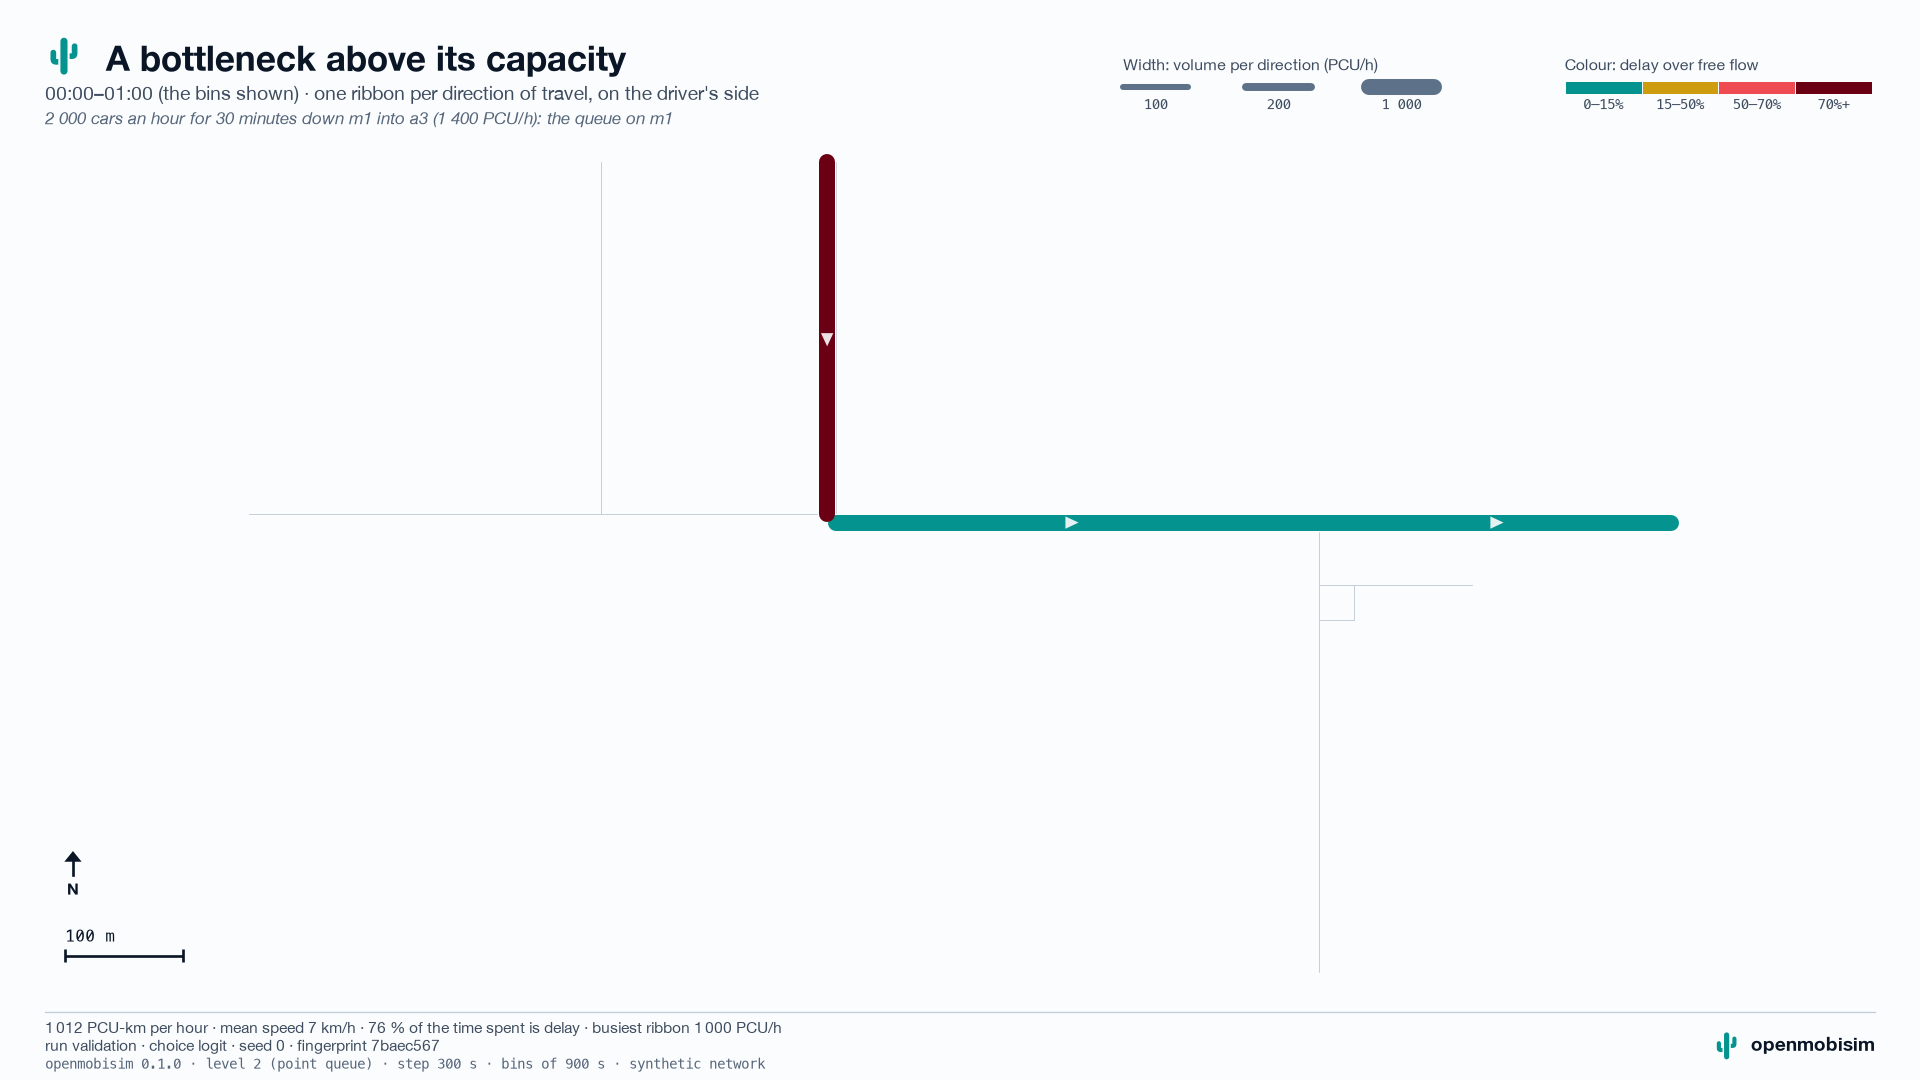

In [7]:
seen = single(cars, link_bin_s=900)
viz.map_link(seen, bins=(0, 4), title="A bottleneck above its capacity",
             note="2 000 cars an hour for 30 minutes down m1 into a3 (1 400 PCU/h): the queue on m1")  # fmt: skip

The simulated delay is within 0.1 % of the theory's (departures and recorded times are whole seconds). The full model
gives the same total: its queue outgrows `m1`'s 84 PCU of storage and backs up to the origin, where the cars wait
off the road; where the delay is spent differs, not how much.

## 3 · Sioux Falls against its published equilibrium

Sioux Falls (24 nodes, 76 links, 528 origin–destination pairs) is the most used benchmark in traffic assignment. Its
published solution (TNTP, Bar-Gera) is a **static user equilibrium**: link costs from the BPR function
`t = t0 · (1 + 0.15 (v/c)⁴)` and every route used being a shortest one. A short Frank–Wolfe solver reproduces its
total cost to within 0.04 % in 200 iterations (Frank–Wolfe approaches the optimum slowly):

In [8]:
sf = ms.examples.case("siouxfalls")
links = pd.read_csv(sf.path("network/links.csv"))
od = pd.read_csv(sf.path("demand/od.csv"))
out = defaultdict(list)
for i, (a, b) in enumerate(zip(links["from"], links["to"], strict=True)):
    out[a].append((b, i))
t0, c0 = links["free_flow_time"].to_numpy(), links["capacity"].to_numpy()


def bpr(v):
    return t0 * (1 + 0.15 * (v / c0) ** 4)


def all_or_nothing(cost, demand):
    y = np.zeros(len(links))
    for o, group in demand.groupby("origin_zone"):
        dist, pred, q = {o: 0.0}, {}, [(0.0, o)]
        while q:
            d, u = heapq.heappop(q)
            if d > dist[u]:
                continue
            for v, i in out[u]:
                if d + cost[i] < dist.get(v, np.inf):
                    dist[v], pred[v] = d + cost[i], i
                    heapq.heappush(q, (d + cost[i], v))
        for dest, n in zip(group["destination_zone"], group["trips"], strict=True):
            node = dest
            while node != o:
                i = pred[node]
                y[i] += n
                node = links["from"][i]
    return y


def static_ue(demand, iterations=200):
    x = all_or_nothing(t0, demand)
    for _ in range(iterations):
        y = all_or_nothing(bpr(x), demand)
        lo, hi = 0.0, 1.0  # the step that minimises Beckmann's objective, by bisection
        for _ in range(40):
            m = (lo + hi) / 2
            lo, hi = (m, hi) if ((y - x) * bpr(x + m * (y - x))).sum() < 0 else (lo, m)
        x = x + (lo + hi) / 2 * (y - x)
    return x


full = od.assign(trips=od["trips"] * 2)  # the bundle's base is half the TNTP matrix
x_full = static_ue(full)
print(f"total cost {np.dot(x_full, bpr(x_full)):,.0f} vehicle-minutes; TNTP publishes 7,480,225")

total cost 7,477,627 vehicle-minutes; TNTP publishes 7,480,225


A **dynamic** model differs from a static one by design: vehicles take time to cross the network, queues hold them
back at bottlenecks instead of a smooth cost slowing everyone, the demand departs over an hour rather than at once,
and travellers choose among routes with a logit model rather than all taking a shortest one. So the two should agree
on the **pattern** (which links carry the traffic) and differ in the **times** (a queue's delay is not BPR's). The
starter case's base scenario is half the TNTP matrix over one hour, a mildly congested morning:

In [9]:
x_base = static_ue(od)
sioux = sf.network()
assert np.allclose(sioux.link_length_m(), links["length"]), "the network keeps the table's link order"
run = sf.scenario("base", link_bin_s=3600).run("siouxfalls-base", quiet=True)
deterministic = sf.scenario("base", link_bin_s=3600, choice_model="deterministic").run("siouxfalls-det", quiet=True)


def volumes(r):
    b = r.link_bins("road")
    return pd.Series(b.pcu()).groupby(b.links()).sum().reindex(range(len(links)), fill_value=0.0).to_numpy()


compare = pd.DataFrame({
    "mean trip (min)": [np.dot(x_base, bpr(x_base)) / od["trips"].sum(), run.mean_travel_time_s / 60,
                        deterministic.mean_travel_time_s / 60],
    "link volumes: correlation with static": [1.0, np.corrcoef(volumes(run), x_base)[0, 1],
                                              np.corrcoef(volumes(deterministic), x_base)[0, 1]],
    "link volumes: mean absolute difference (veh)": [0.0, np.abs(volumes(run) - x_base).mean(),
                                                     np.abs(volumes(deterministic) - x_base).mean()],
}, index=["static equilibrium (BPR)", "openmobisim, logit (default)", "openmobisim, deterministic choice"])
compare.round(3)  # fmt: skip

,mean trip (min),link volumes: correlation with static,link volumes: mean absolute difference (veh)
static equilibrium (BPR),10.374,1.000,0.000
"openmobisim, logit (default)",13.171,0.817,1184.536
"openmobisim, deterministic choice",12.723,0.862,1021.803


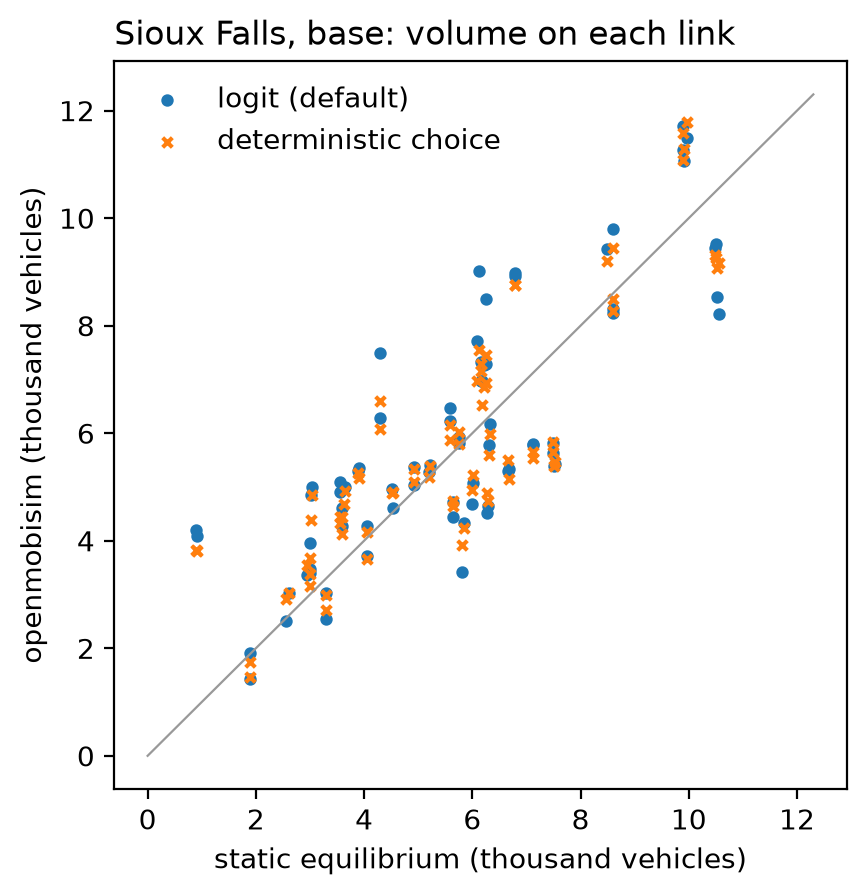

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12 / 2.54, 12 / 2.54), dpi=200)
ax.scatter(x_base / 1000, volumes(run) / 1000, s=12, label="logit (default)")
ax.scatter(x_base / 1000, volumes(deterministic) / 1000, s=12, marker="x", label="deterministic choice")
top = max(x_base.max(), volumes(run).max()) / 1000 * 1.05
ax.plot([0, top], [0, top], color="0.6", linewidth=0.8)
ax.set_xlabel("static equilibrium (thousand vehicles)")
ax.set_ylabel("openmobisim (thousand vehicles)")
ax.set_title("Sioux Falls, base: volume on each link", loc="left")
ax.legend(frameon=False)
plt.show()

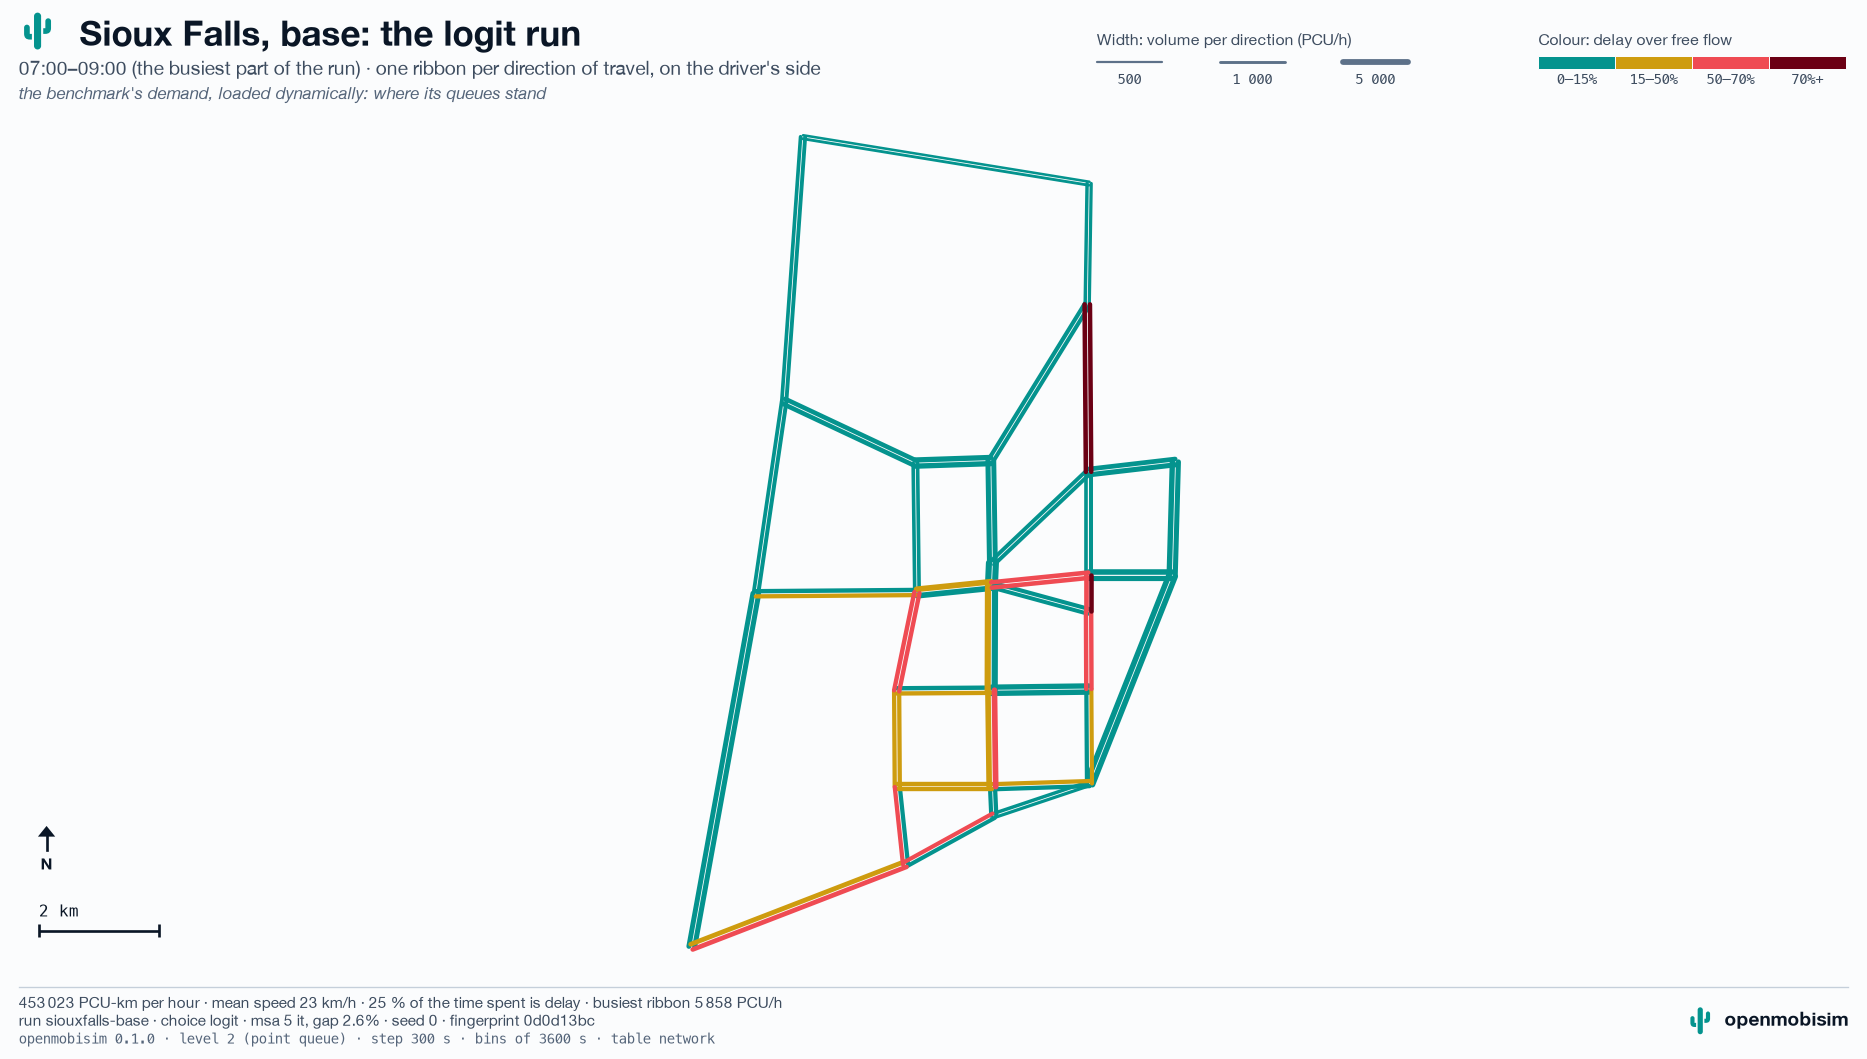

In [11]:
viz.map_link(run, title="Sioux Falls, base: the logit run",
             note="the benchmark's demand, loaded dynamically: where its queues stand")  # fmt: skip

The pattern agrees; the dynamic model's mean trip is longer than the static one's because its queues delay the
vehicles behind a bottleneck by the full queue, where BPR spreads a milder delay over everyone on the link.

**What this does not show.** None of it calibrates the model to a real place: that needs counts and travel times of
the place, and the parameters notebook 06 lists. It shows that the mechanisms compute what they are said to.

**Next:** [08 · Performance](08_performance.ipynb): performance: a city's run time, where the time goes, samples for speed. The whole series: [00 · overview](00_getting_started.ipynb). The documentation: [openmobisim.github.io](https://openmobisim.github.io). Something wrong or unclear? [Report it](https://github.com/bahmanmdd/openmobisim/issues).